# 05 — YOLO data overview, annotation checks and visualization

This is the first notebook of the **object-detection (YOLOv8)** pipeline. It
works on the YOLO-format dataset stored in `data/archive/`, which contains
images **and** one `.txt` annotation file per image.

The notebook:

1. scans the archive and discovers the `Train` / `Val` folders;
2. pairs every image with its `.txt` annotation by comparing file base names;
3. reports images without annotation and annotations without image;
4. validates the YOLO format (5 columns, class id, normalized coordinates);
5. checks that the classes written in the annotations match the class folders;
6. visualizes class distributions and sample images with their bounding boxes;
7. saves a validated manifest for notebook 06.

Nothing is copied or modified here: this notebook only **reads** `data/archive`
and writes reports under `data/processed/`.

> **How to read this notebook:** every code cell is preceded by a short
> summary that explains what the step does and how to interpret its output.

## 1. Imports and paths

Imports the libraries, defines the class names and maps each class folder of
the archive to a YOLO class id.

The id order is the one used by the annotations: `0 = Glioma`,
`1 = Meningioma`, `2 = No Tumor`, `3 = Pituitary`.

**How to read the output:** the three printed paths must be the raw archive,
the processed folder and the manifest that this notebook will write.

In [1]:
from pathlib import Path
import collections
import json
import random

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd

ROOT_DIR = Path.cwd()
if ROOT_DIR.name == "notebooks":
    ROOT_DIR = ROOT_DIR.parent

ARCHIVE_DIR = ROOT_DIR / "data" / "archive"
PROCESSED_DIR = ROOT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = PROCESSED_DIR / "yolo_manifest.json"

CLASS_NAMES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
ID_TO_CLASS = {i: name for name, i in CLASS_TO_ID.items()}
SPLITS = ["Train", "Val"]
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp")
SEED = 42

print("Archive :", ARCHIVE_DIR)
print("Processed:", PROCESSED_DIR)
print("Manifest :", MANIFEST_PATH)

Archive : /home/fangyuan/Projects/Diagnostic-des-tumeurs/data/archive
Processed: /home/fangyuan/Projects/Diagnostic-des-tumeurs/data/processed
Manifest : /home/fangyuan/Projects/Diagnostic-des-tumeurs/data/processed/yolo_manifest.json


## 2. Scan the archive and pair images with annotations

Walks `data/archive/{split}/{class}/images` and `.../labels`, keeps the files
with a valid image extension and pairs them by **file stem**: `image(12).jpg`
must have an `image(12).txt`.

An image without a `.txt` is collected as *missing label*; a `.txt` without an
image is collected as *missing image*. Both will be excluded from the dataset
in notebook 06.

**How to read the output:** the table shows the number of paired images per
split and class. In this archive `Train` has 4737 images and `Val` has 512 images, of
which 510 have a matching annotation.

In [2]:
if not ARCHIVE_DIR.exists():
    raise FileNotFoundError(
        f"Archive not found: {ARCHIVE_DIR}\n"
        "Expected data/archive/Train/<class>/images and .../labels"
    )


def relative(path: Path) -> str:
    return path.relative_to(ROOT_DIR).as_posix()


records = {split: [] for split in SPLITS}
discarded = {"missing_labels": [], "missing_images": []}
folder_counts = []

for split in SPLITS:
    split_dir = ARCHIVE_DIR / split
    if not split_dir.exists():
        raise FileNotFoundError(f"{split_dir} not found")

    for folder in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        if folder.name not in CLASS_TO_ID:
            raise ValueError(
                f"Unknown class folder {folder.name!r} in {split}. "
                f"Expected one of {CLASS_NAMES}."
            )

        images_dir = folder / "images"
        labels_dir = folder / "labels"
        if not images_dir.exists() or not labels_dir.exists():
            print(f"[warn] {folder} has no images/ or labels/ folder: skipped")
            continue

        images = {
            p.stem: p
            for p in sorted(images_dir.iterdir())
            if p.suffix.lower() in IMAGE_EXTENSIONS
        }
        labels = {
            p.stem: p
            for p in sorted(labels_dir.iterdir())
            if p.suffix.lower() == ".txt"
        }

        for stem, image_path in images.items():
            label_path = labels.get(stem)
            if label_path is None:
                discarded["missing_labels"].append(
                    {"path": relative(image_path), "split": split, "folder": folder.name}
                )
                continue
            records[split].append(
                {
                    "image": relative(image_path),
                    "label": relative(label_path),
                    "split": split,
                    "folder": folder.name,
                    "folder_class": CLASS_TO_ID[folder.name],
                    "stem": stem,
                }
            )

        for stem, label_path in labels.items():
            if stem not in images:
                discarded["missing_images"].append(
                    {"path": relative(label_path), "split": split, "folder": folder.name}
                )

        folder_counts.append(
            {
                "split": split,
                "folder": folder.name,
                "images": len(images),
                "labels": len(labels),
                "paired": sum(1 for stem in images if stem in labels),
            }
        )

paired_df = pd.DataFrame(folder_counts)
display(paired_df.pivot(index="folder", columns="split", values="paired").reindex(CLASS_NAMES))
print("Total paired images:", sum(len(records[s]) for s in SPLITS))

split,Train,Val
folder,,
Glioma,1153,136
Meningioma,1449,140
No Tumor,711,98
Pituitary,1424,136


Total paired images: 5247


## 3. Report unmatched files

Shows the images that have no annotation and the annotations that have no
image, for every split and class.

**How to read the output:** `0` is the ideal result. In this archive
`Val/No Tumor` has 2 images without label and 2 labels without image, so four
files will be discarded. A non-zero value is not fatal, but the files must be
excluded before training, otherwise YOLO would try to load a missing file.

In [3]:
missing_labels_df = pd.DataFrame(discarded["missing_labels"])
missing_images_df = pd.DataFrame(discarded["missing_images"])

print("Images without annotation:", len(missing_labels_df))
if not missing_labels_df.empty:
    display(missing_labels_df)

print("Annotations without image:", len(missing_images_df))
if not missing_images_df.empty:
    display(missing_images_df)

if missing_labels_df.empty and missing_images_df.empty:
    print("Every image has its annotation and every annotation has its image.")

Images without annotation: 2


,path,split,folder
0,data/archive/Val/No Tumor/images/image(55).jpg,Val,No Tumor
1,data/archive/Val/No Tumor/images/image(61).jpg,Val,No Tumor


Annotations without image: 2


,path,split,folder
0,data/archive/Val/No Tumor/labels/image(53).txt,Val,No Tumor
1,data/archive/Val/No Tumor/labels/image(60).txt,Val,No Tumor


## 4. Validate the YOLO annotation format

Parses every annotation and checks that:

- each non-empty line has exactly **5 values**;
- the class id is an integer between `0` and `3`;
- pixel coordinates are **normalized** (`x, y, w, h` in `[0, 1]`);
- the width and height are strictly positive;
- the box stays inside the image (`x ± w/2` and `y ± h/2` in `[0, 1]`).

An empty `.txt` is valid: it means a background image with no object. Lines
that fail a check are reported and the image is flagged as invalid.

**How to read the output:** `Invalid files` must be `0`. If some appear, the
table gives the file, the line number and the reason, so the annotation can be
fixed before training.

In [4]:
def parse_yolo_label(path: Path):
    """Return (boxes, errors) for one YOLO .txt file.

    boxes are (class_id, x_center, y_center, width, height) with normalized
    coordinates.
    """
    boxes, errors = [], []
    text = path.read_text().strip()
    if not text:
        # Empty file = background image (no object).
        return boxes, errors

    for line_no, line in enumerate(text.splitlines(), start=1):
        parts = line.split()
        if len(parts) != 5:
            errors.append(f"line {line_no}: expected 5 values, got {len(parts)}")
            continue
        try:
            class_id = int(parts[0])
            x, y, w, h = (float(value) for value in parts[1:])
        except ValueError:
            errors.append(f"line {line_no}: non-numeric value")
            continue

        if not 0 <= class_id < len(CLASS_NAMES):
            errors.append(f"line {line_no}: class id {class_id} out of range")
            continue
        if not all(0.0 <= value <= 1.0 for value in (x, y, w, h)):
            errors.append(f"line {line_no}: coordinates not in [0, 1]")
            continue
        if w <= 0 or h <= 0:
            errors.append(f"line {line_no}: width/height must be positive")
            continue
        if (
            x - w / 2 < -1e-6
            or x + w / 2 > 1 + 1e-6
            or y - h / 2 < -1e-6
            or y + h / 2 > 1 + 1e-6
        ):
            errors.append(f"line {line_no}: box crosses the image border")
            continue

        boxes.append((class_id, x, y, w, h))

    return boxes, errors


invalid_rows = []
for split in SPLITS:
    for record in records[split]:
        boxes, errors = parse_yolo_label(ROOT_DIR / record["label"])
        record["boxes"] = boxes
        record["label_classes"] = sorted({int(box[0]) for box in boxes})
        record["consistent"] = set(record["label_classes"]) <= {record["folder_class"]}
        record["valid"] = not errors
        record["errors"] = errors
        if errors:
            invalid_rows.append(
                {
                    "label": record["label"],
                    "split": split,
                    "errors": "; ".join(errors),
                }
            )

invalid_df = pd.DataFrame(invalid_rows)
print("Checked annotation files:", sum(len(records[s]) for s in SPLITS))
print("Invalid files          :", len(invalid_df))
if not invalid_df.empty:
    display(invalid_df)

Checked annotation files: 5247
Invalid files          : 0


## 5. Check class consistency with the folders

Compares the class id written in each annotation with the class of the folder
the image belongs to. For example, an image stored in `Glioma/` should
normally contain class `0` boxes.

**How to read the output:** the crosstab shows the folder class (rows) against
the classes actually present in the annotations (columns). Several images
contain a second box of another class (for instance a Glioma image with a
small class-3 box). They are **kept as-is**: the class written in the `.txt`
is the annotation of record, and the folder is only used to stratify the
train/valid/test split. The printed count tells you how many images are
affected.

In [5]:
consistency_rows = []
for split in SPLITS:
    for record in records[split]:
        consistency_rows.append(
            {
                "split": split,
                "folder": record["folder"],
                "folder_class": record["folder_class"],
                "label_classes": ",".join(str(c) for c in record["label_classes"]) or "(empty)",
                "consistent": set(record["label_classes"]) <= {record["folder_class"]},
            }
        )

consistency_df = pd.DataFrame(consistency_rows)

display(
    pd.crosstab(
        consistency_df["folder"],
        consistency_df["label_classes"],
        margins=True,
    ).rename_axis(index="folder", columns="classes in annotation")
)

mixed = consistency_df.loc[~consistency_df["consistent"]]
print("Images whose annotation contains a class from another folder:", len(mixed))
if not mixed.empty:
    display(mixed.head(10))

classes in annotation,(empty),0,"0,1","0,3",1,"1,3",2,3,All
folder,,,,,,,,,
Glioma,1,1123,1,161,2,0,0,1,1289
Meningioma,0,2,0,0,1483,95,0,9,1589
No Tumor,0,0,0,0,0,0,809,0,809
Pituitary,0,0,0,0,1,0,0,1559,1560
All,1,1125,1,161,1486,95,809,1569,5247


Images whose annotation contains a class from another folder: 272


,split,folder,folder_class,label_classes,consistent
18,Train,Glioma,0,"0,3",False
21,Train,Glioma,0,"0,1",False
22,Train,Glioma,0,"0,3",False
23,Train,Glioma,0,1,False
24,Train,Glioma,0,"0,3",False
29,Train,Glioma,0,"0,3",False
30,Train,Glioma,0,"0,3",False
33,Train,Glioma,0,"0,3",False
35,Train,Glioma,0,"0,3",False
45,Train,Glioma,0,"0,3",False


## 6. Class and split distribution

Counts the paired images per folder and the annotated boxes per class.

**How to read the output:** the left chart is what the model will see as
images; the right chart is what it has to detect. The two counts differ because
one image can contain several boxes, and because some boxes belong to a class
different from the folder.

split,Train,Val
folder,,
Glioma,1153,136
Meningioma,1449,140
No Tumor,711,98
Pituitary,1424,136


,Train,Val
class,,
Glioma,1152,135
Meningioma,1442,140
No Tumor,711,98
Pituitary,1671,154


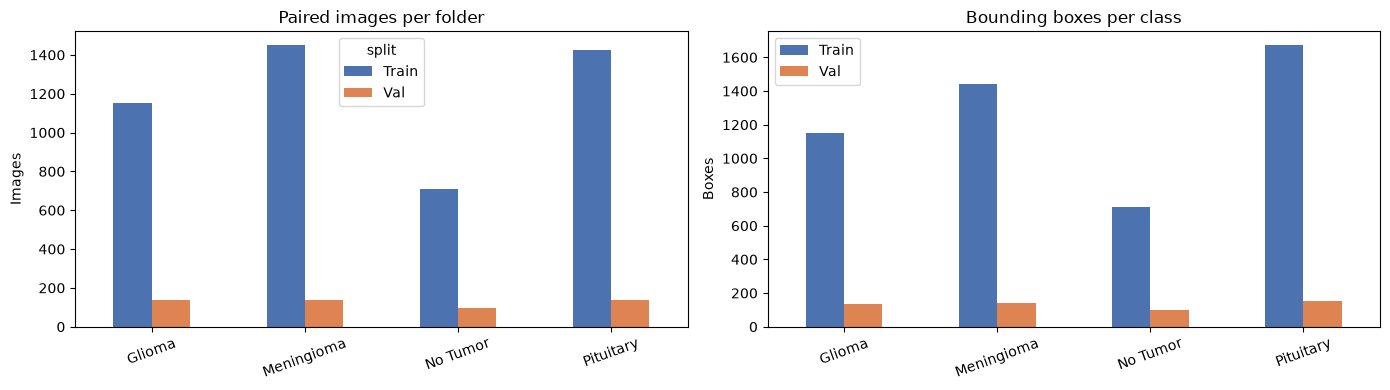

In [6]:
image_counts = pd.DataFrame(folder_counts)
image_pivot = (
    image_counts.pivot(index="folder", columns="split", values="paired")
    .reindex(CLASS_NAMES)
    .fillna(0)
    .astype(int)
)

instance_counts = collections.Counter()
for split in SPLITS:
    for record in records[split]:
        for class_id in record["label_classes"]:
            instance_counts[(split, class_id)] += 1

instance_pivot = pd.DataFrame(
    {
        "class": [ID_TO_CLASS[class_id] for class_id in range(len(CLASS_NAMES))],
        **{
            split: [
                instance_counts[(split, class_id)]
                for class_id in range(len(CLASS_NAMES))
            ]
            for split in SPLITS
        },
    }
).set_index("class")

display(image_pivot)
display(instance_pivot)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
image_pivot.plot(kind="bar", ax=axes[0], color=["#4c72b0", "#dd8452"])
axes[0].set_title("Paired images per folder")
axes[0].set_xlabel("")
axes[0].set_ylabel("Images")
axes[0].tick_params(axis="x", rotation=20)

instance_pivot.plot(kind="bar", ax=axes[1], color=["#4c72b0", "#dd8452"])
axes[1].set_title("Bounding boxes per class")
axes[1].set_xlabel("")
axes[1].set_ylabel("Boxes")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## 7. Check image readability, size and channels

Reads the header of every paired image to confirm it can be decoded, then
records its width, height and channel count.

**How to read the output:** `Unreadable images` must be `0` and the channel
count should be `3` (RGB). Resolutions vary a lot (mostly 512x512, but some
images are 225x225 or rectangular); YOLO resizes/letterboxes them to `imgsz`
during training, so no manual resizing is needed.

Checked images   : 5247
Unreadable images: 0
Channel counts   : {3: 5247}

Most common resolutions (width x height):
width  height
512    512       4206
225    225        119
630    630         66
442    442         42
236    236         33
256    256         25
201    251         23
       250         22
214    236         18
468    444         15


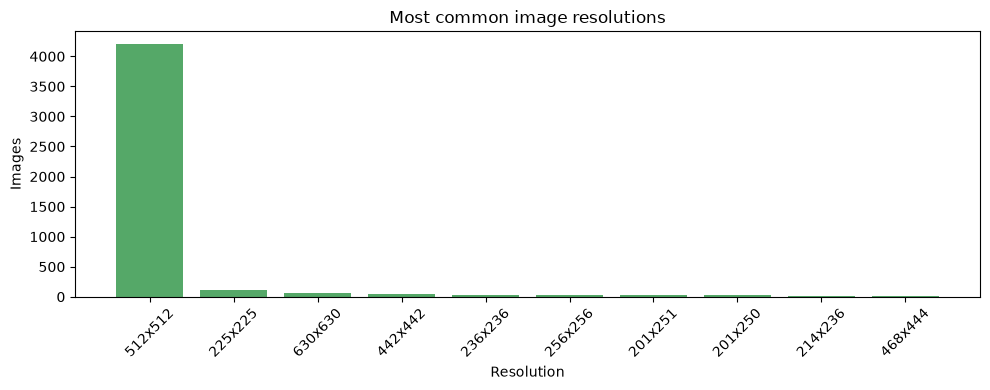

In [7]:
image_checks = []
for split in SPLITS:
    for record in records[split]:
        image = cv2.imread(str(ROOT_DIR / record["image"]))
        if image is None:
            image_checks.append(
                {
                    "image": record["image"],
                    "readable": False,
                    "width": None,
                    "height": None,
                    "channels": None,
                }
            )
            continue
        height, width = image.shape[:2]
        channels = image.shape[2] if image.ndim == 3 else 1
        image_checks.append(
            {
                "image": record["image"],
                "readable": True,
                "width": width,
                "height": height,
                "channels": channels,
            }
        )

checks_df = pd.DataFrame(image_checks)
unreadable_df = checks_df.loc[~checks_df["readable"]]

print("Checked images   :", len(checks_df))
print("Unreadable images:", len(unreadable_df))
print("Channel counts   :", checks_df["channels"].value_counts(dropna=False).to_dict())

size_counts = (
    checks_df.dropna(subset=["width", "height"])
    .groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
)
print("\nMost common resolutions (width x height):")
print(size_counts.head(10).to_string())

plt.figure(figsize=(10, 4))
labels = [f"{int(w)}x{int(h)}" for w, h in size_counts.head(10).index]
plt.bar(labels, size_counts.head(10).values, color="#55a868")
plt.title("Most common image resolutions")
plt.xlabel("Resolution")
plt.ylabel("Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Display sample images with bounding boxes

Draws two random training images per class, with every annotated box and its
class name.

**How to read the output:** each box should surround a plausible tumor region,
and the label above it must match the annotation. This is the visual check
that the pairing and parsing worked: if a box is drawn in the wrong place, the
normalization convention of the annotation is wrong.

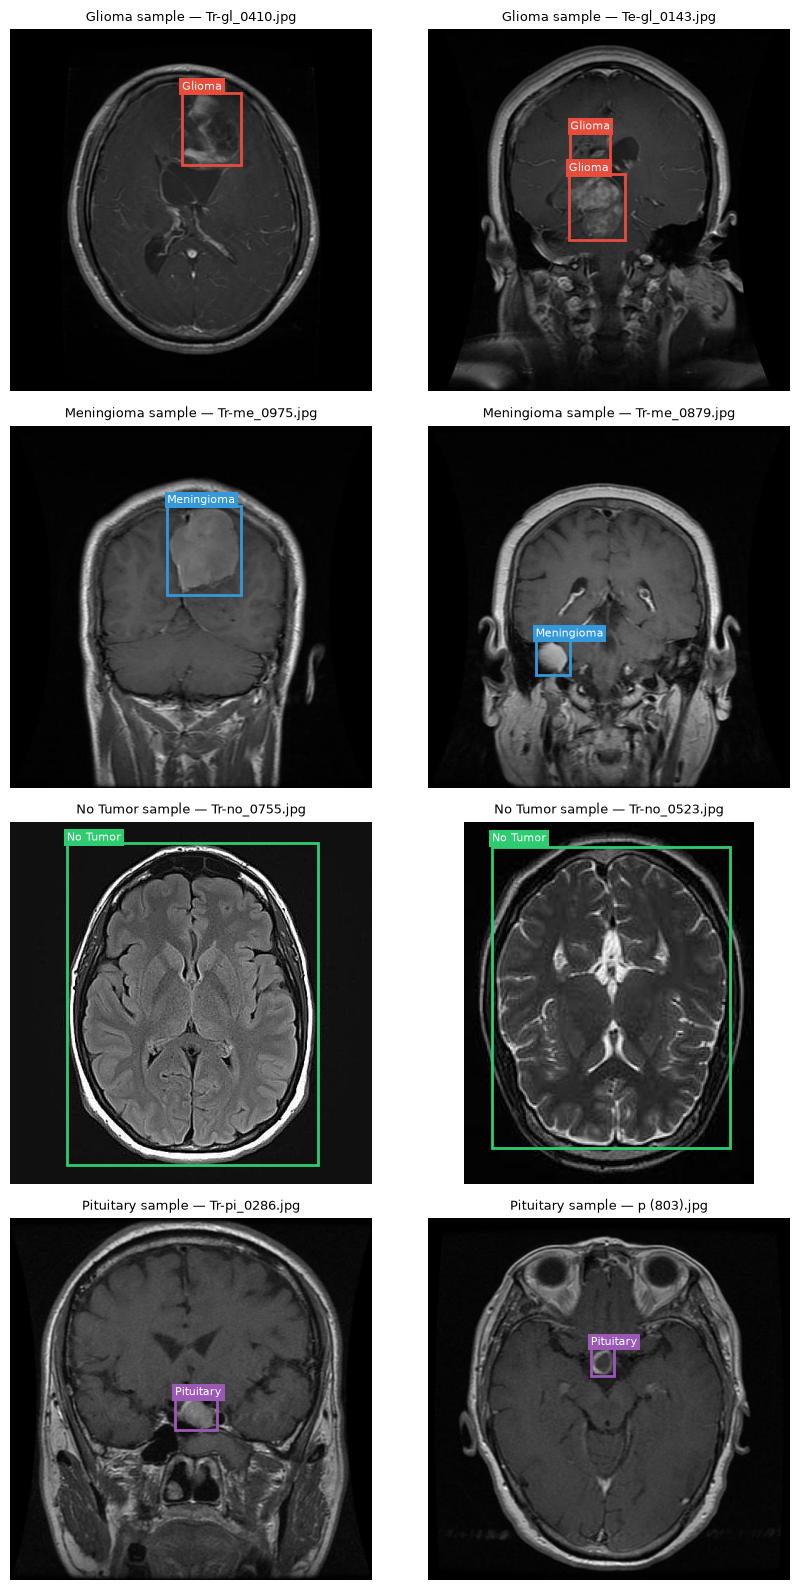

In [8]:
CLASS_COLORS = {
    0: "#e74c3c",
    1: "#3498db",
    2: "#2ecc71",
    3: "#9b59b6",
}


def draw_boxes(axis, image_path: Path, boxes):
    image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]
    axis.imshow(image)
    axis.axis("off")
    for class_id, x, y, w, h in boxes:
        x1 = (x - w / 2) * width
        y1 = (y - h / 2) * height
        axis.add_patch(
            patches.Rectangle(
                (x1, y1),
                w * width,
                h * height,
                linewidth=2,
                edgecolor=CLASS_COLORS[class_id],
                facecolor="none",
            )
        )
        axis.text(
            x1,
            max(y1 - 4, 8),
            ID_TO_CLASS[class_id],
            color="white",
            fontsize=8,
            bbox={"facecolor": CLASS_COLORS[class_id], "pad": 2, "edgecolor": "none"},
        )


random.seed(SEED)
fig, axes = plt.subplots(len(CLASS_NAMES), 2, figsize=(9, 4 * len(CLASS_NAMES)))

for row, class_id in enumerate(range(len(CLASS_NAMES))):
    candidates = [
        record
        for record in records["Train"]
        if record["valid"]
        and record["boxes"]
        and record["folder_class"] == class_id
    ]
    samples = random.sample(candidates, 2)
    for col, record in enumerate(samples):
        draw_boxes(axes[row, col], ROOT_DIR / record["image"], record["boxes"])
        axes[row, col].set_title(
            f"{ID_TO_CLASS[class_id]} sample — {record['image'].split('/')[-1]}",
            fontsize=9,
        )

plt.tight_layout()
plt.show()

## 9. Save the validated manifest

Writes `data/processed/yolo_manifest.json`, which notebook 06 uses to copy the
files. It contains the paired records with their parsed boxes, the discarded
files and the validation summary.

**How to read the output:** the printed totals must match the tables above:
`Train` 4737 paired images, `Val` 512 paired images, 4 discarded files.

In [9]:
manifest = {
    "created_by": "05_yolo_data_overview.ipynb",
    "source_dir": relative(ARCHIVE_DIR),
    "format": "YOLO detection: class x_center y_center width height (normalized)",
    "classes": CLASS_NAMES,
    "class_to_id": CLASS_TO_ID,
    "id_to_class": {str(k): v for k, v in ID_TO_CLASS.items()},
    "seed": SEED,
    "splits": {
        split: [
            {
                "image": record["image"],
                "label": record["label"],
                "split": record["split"],
                "folder": record["folder"],
                "folder_class": int(record["folder_class"]),
                "stem": record["stem"],
                "boxes": [
                    [int(class_id), float(x), float(y), float(w), float(h)]
                    for class_id, x, y, w, h in record["boxes"]
                ],
                "label_classes": [int(c) for c in record["label_classes"]],
                "consistent": bool(record["consistent"]),
                "valid": bool(record["valid"]),
                "errors": record["errors"],
            }
            for record in records[split]
        ]
        for split in SPLITS
    },
    "discarded": discarded,
    "counts": {
        "paired_per_split": {split: len(records[split]) for split in SPLITS},
        "invalid_annotations": len(invalid_df),
        "missing_labels": len(discarded["missing_labels"]),
        "missing_images": len(discarded["missing_images"]),
        "images_per_folder": image_pivot.to_dict(),
        "boxes_per_class": instance_pivot.to_dict(),
    },
    "image_checks": {
        "unreadable": unreadable_df["image"].tolist(),
        "most_common_sizes": {
            f"{int(w)}x{int(h)}": int(count)
            for (w, h), count in size_counts.head(10).items()
        },
    },
}

with open(MANIFEST_PATH, "w") as handle:
    json.dump(manifest, handle, indent=2)

print("Manifest saved:", MANIFEST_PATH)
print("Size:", round(MANIFEST_PATH.stat().st_size / 1024, 1), "KB")

Manifest saved: /home/fangyuan/Projects/Diagnostic-des-tumeurs/data/processed/yolo_manifest.json
Size: 2870.7 KB


## 10. Reload and verify the manifest

Reads the file back and recomputes the totals from its content.

**How to read the output:** the three lines must be identical to the counts
printed in steps 2 and 5. If they differ, the manifest is corrupted and
notebook 06 would build an incomplete dataset.

In [10]:
with open(MANIFEST_PATH) as handle:
    saved = json.load(handle)

totals = {split: len(saved["splits"][split]) for split in SPLITS}
print("Train paired images:", totals["Train"])
print("Val paired images  :", totals["Val"])
print("Valid annotations  :", sum(r["valid"] for s in SPLITS for r in saved["splits"][s]))
print("Discarded files    :", saved["counts"]["missing_labels"] + saved["counts"]["missing_images"])

assert totals == saved["counts"]["paired_per_split"]
print("Manifest OK — ready for 06_yolo_preprocessing.ipynb")

Train paired images: 4737
Val paired images  : 510
Valid annotations  : 5247
Discarded files    : 4
Manifest OK — ready for 06_yolo_preprocessing.ipynb


## Next step

Open **`06_yolo_preprocessing.ipynb`**. It copies the paired files into
`data/yolo/images/{train,valid,test}`, splits the `Val` archive into a
validation and a test set, writes `data/yolo/data.yaml` and defines the
augmentation configuration used for training.